<a href="https://colab.research.google.com/github/Agostinho-Escovalo/Traffic-Sign-Recognition/blob/main/traffic_sign_recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LOADING AND PREPARING DATA FOR TRAINING (ЗАГРУЗКА И ПОДГАТОВКА ДАННЫХ К ОБУЧЕНИЮ)

In [ ]:
import os

# Create a catalog (Создать каталог)
!mkdir -p /content/gtsrb

# Download training data (Скачать обучающие данные)
!wget --no-check-certificate \
  https://sid.erda.dk/public/archives/daaeac0d7ce1152aea9b61d9f1e19370/GTSRB-Training_fixed.zip \
  -O /content/gtsrb/train.zip

# Download test images (Скачать тестовые изображения)
!wget --no-check-certificate \
  https://sid.erda.dk/public/archives/daaeac0d7ce1152aea9b61d9f1e19370/GTSRB_Final_Test_Images.zip \
  -O /content/gtsrb/test_images.zip

# Download test labels (Скачать тестовые этикетки)
!wget --no-check-certificate \
  https://sid.erda.dk/public/archives/daaeac0d7ce1152aea9b61d9f1e19370/GTSRB_Final_Test_GT.zip \
  -O /content/gtsrb/test_labels.zip

--2026-11-15 19:42:14--  https://sid.erda.dk/public/archives/daaeac0d7ce1152aea9b61d9f1e19370/GTSRB-Training_fixed.zip
Resolving sid.erda.dk (sid.erda.dk)... 130.225.104.13
Connecting to sid.erda.dk (sid.erda.dk)|130.225.104.13|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 187490228 (179M) [application/zip]
Saving to: ‘/content/gtsrb/train.zip’

/content/gtsrb/trai 100%[===================>] 178.80M  12.4MB/s    in 16s     

2026-11-15 19:42:31 (11.2 MB/s) - ‘/content/gtsrb/train.zip’ saved [187490228/187490228]

--2026-11-15 19:42:31--  https://sid.erda.dk/public/archives/daaeac0d7ce1152aea9b61d9f1e19370/GTSRB_Final_Test_Images.zip
Resolving sid.erda.dk (sid.erda.dk)... 130.225.104.13
Connecting to sid.erda.dk (sid.erda.dk)|130.225.104.13|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 88978620 (85M) [application/zip]
Saving to: ‘/content/gtsrb/test_images.zip’

/content/gtsrb/test 100%[===================>]  84.86M  5.43MB/s    in

In [ ]:
!unzip -q /content/gtsrb/train.zip -d /content/gtsrb/
!unzip -q /content/gtsrb/test_images.zip -d /content/gtsrb/
!unzip -q /content/gtsrb/test_labels.zip -d /content/gtsrb/

In [ ]:
import os
from PIL import Image
from pathlib import Path

# Source and target folders (Исходная и целевая папки)
src_dir = '/content/gtsrb/GTSRB/Training'
dst_dir = '/content/gtsrb/GTSRB/Training_png'

# Create a target directory (Создать целевой каталог)
os.makedirs(dst_dir, exist_ok=True)

print("Converting images from PPM to PNG format....")

for class_folder in os.listdir(src_dir):
    src_class_path = os.path.join(src_dir, class_folder)
    dst_class_path = os.path.join(dst_dir, class_folder)

    if not os.path.isdir(src_class_path):
        continue

    os.makedirs(dst_class_path, exist_ok=True)

    # Convert each image to .ppm (Преобразовать каждое изображение .ppm)
    for filename in os.listdir(src_class_path):
        if filename.endswith('.ppm'):
            src_file = os.path.join(src_class_path, filename)
            dst_file = os.path.join(dst_class_path, filename.replace('.ppm', '.png'))

            try:
                with Image.open(src_file) as img:
                    img.save(dst_file, 'PNG')
            except Exception as e:
                print(f"Conversion error {src_file}: {e}")

print("The transformation is complete!")

Converting images from PPM to PNG format....
The transformation is complete!


In [ ]:
import tensorflow as tf

train_ds = tf.keras.utils.image_dataset_from_directory(
    '/content/gtsrb/GTSRB/Training_png',
    labels='inferred',
    label_mode='int',
    color_mode='rgb',
    batch_size=32,
    image_size=(32, 32),
    shuffle=True,
    seed=42
)

print(f"Classes: {len(train_ds.class_names)}")

Found 26640 files belonging to 43 classes.
Classes: 43


In [ ]:
src_test = '/content/gtsrb/GTSRB/Final_Test/Images'
dst_test = '/content/gtsrb/GTSRB/Final_Test/Images_png'

os.makedirs(dst_test, exist_ok=True)

for filename in os.listdir(src_test):
    if filename.endswith('.ppm'):
        src_file = os.path.join(src_test, filename)
        dst_file = os.path.join(dst_test, filename.replace('.ppm', '.png'))
        with Image.open(src_file) as img:
            img.save(dst_file, 'PNG')

print("Test images converted to format PNG..")

Test images converted to format PNG..


Total number of training images: 26640
Number of classes: 43
Images by class — Min: 150, Max: 1500, Media: 619.5


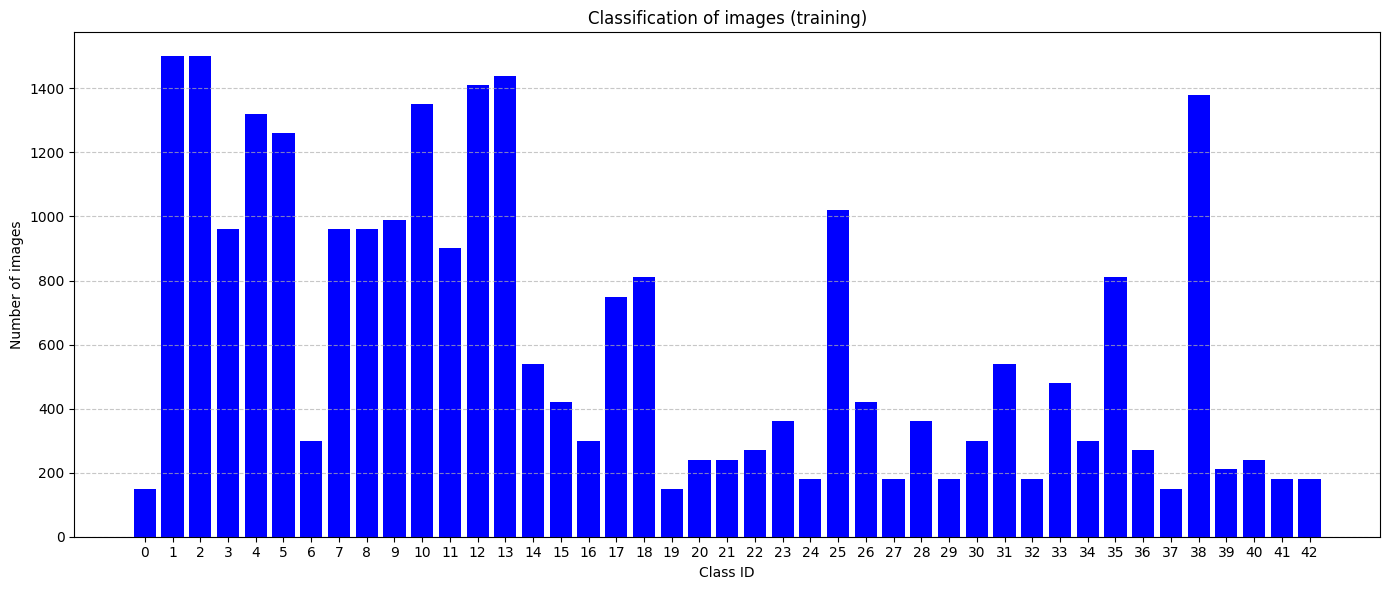

In [ ]:
import os
from collections import Counter
import matplotlib.pyplot as plt

train_dir = '/content/gtsrb/GTSRB/Training_png'  # Folder after conversion to format PNG.

# Number of images by class.
class_counts = {}
for class_folder in sorted(os.listdir(train_dir)):
    folder_path = os.path.join(train_dir, class_folder)
    if os.path.isdir(folder_path):
        count = len([f for f in os.listdir(folder_path) if f.endswith('.png')])
        class_id = int(class_folder)  # '00000' → 0
        class_counts[class_id] = count

# Sort by class ID
class_ids = sorted(class_counts.keys())
counts = [class_counts[cid] for cid in class_ids]

total_images = sum(counts)
print(f"Total number of training images: {total_images}")
print(f"Number of classes: {len(counts)}")
print(f"Images by class — Min: {min(counts)}, Max: {max(counts)}, Media: {total_images/len(counts):.1f}")

# Bar's graphic
plt.figure(figsize=(14, 6))
plt.bar(class_ids, counts, color='blue')
plt.xlabel('Class ID')
plt.ylabel('Number of images')
plt.title('Classification of images (training)')
plt.xticks(range(0, 43, 1))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

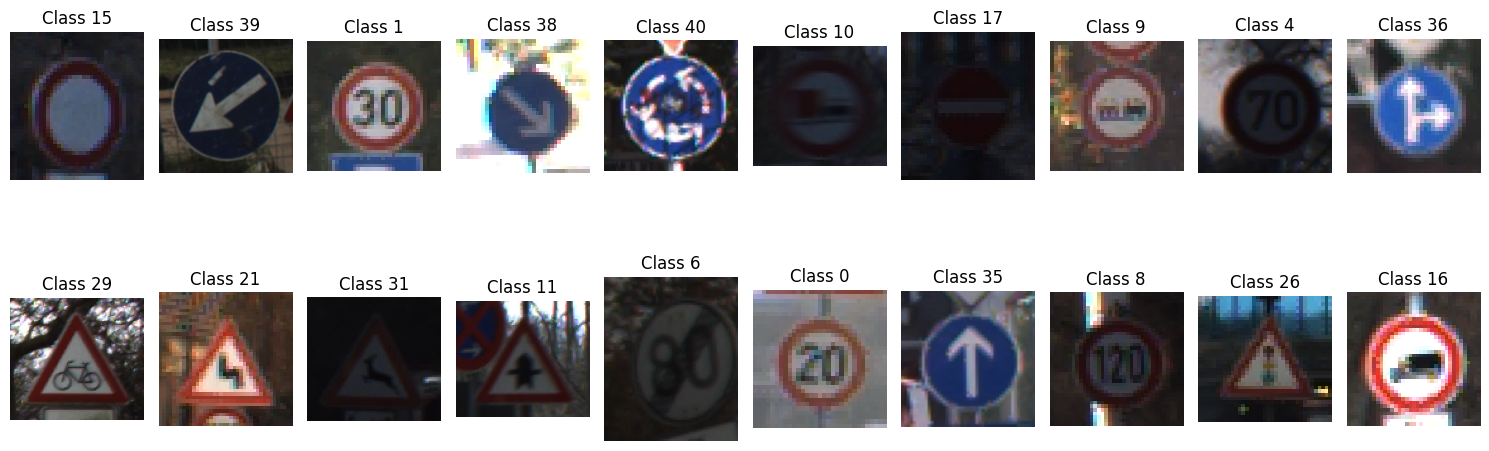

In [ ]:
# Examples (taken from different classes).
import random

plt.figure(figsize=(15, 6))
sampled = 0
for class_id in random.sample(class_ids, 20):
    folder = os.path.join(train_dir, f"{class_id:05d}")
    files = os.listdir(folder)
    if files:
        img_path = os.path.join(folder, random.choice(files))
        img = Image.open(img_path)
        plt.subplot(2, 10, sampled + 1)
        plt.imshow(img)
        plt.title(f"Class {class_id}")
        plt.axis('off')
        sampled += 1
        if sampled >= 20:
            break
plt.tight_layout()
plt.show()

In [ ]:
# Parameters
IMG_SIZE = 32
BATCH_SIZE = 32

# Path to the dataset (already converted to format PNG)
data_dir = '/content/gtsrb/GTSRB/Training_png'

# Download the dataset whitout resizing.
raw_train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    labels='inferred',
    label_mode='int',
    color_mode='rgb',
    batch_size=BATCH_SIZE,
    image_size=(IMG_SIZE, IMG_SIZE),
    shuffle=True,
    seed=42
)

Found 26640 files belonging to 43 classes.


Parameters: (32, 32, 32, 3)
Minimum value: 0.0
Maximum value: 1.0


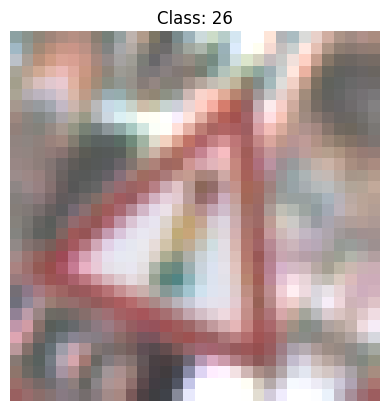

In [ ]:
# Image from the dataset.
for image_batch, labels_batch in train_ds.take(1):
    print("Parameters:", image_batch.shape)   # (32, 32, 32, 3)
    print("Minimum value:", image_batch.numpy().min())  # ~0.0
    print("Maximum value:", image_batch.numpy().max())  # ~1.0

    plt.imshow(image_batch[0].numpy())
    plt.title(f"Class: {labels_batch[0]}")
    plt.axis('off')
    plt.show()
    break

In [ ]:
# Augmentation layer
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomBrightness(0.15),
    tf.keras.layers.RandomContrast(0.1),
], name="data_augmentation")

In [ ]:
IMG_SIZE = 32
BATCH_SIZE = 32

# Loading a dataset with automatic resizing
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    '/content/gtsrb/GTSRB/Training_png',
    labels='inferred',
    label_mode='int',
    color_mode='rgb',
    batch_size=BATCH_SIZE,
    image_size=(IMG_SIZE, IMG_SIZE),
    shuffle=True,
    seed=42
)

# Normalization (for [0,1])
normalization_layer = tf.keras.layers.Rescaling(1./255)

# Apply augmentation + normalization
def augment_and_normalize(image, label):
    image = tf.cast(image, tf.float32)
    image = data_augmentation(image)
    image = normalization_layer(image)
    return image, label

# Apply to dataset
train_ds = train_ds_raw.map(augment_and_normalize, num_parallel_calls=tf.data.AUTOTUNE)

Found 26640 files belonging to 43 classes.


In [ ]:
total_batches = train_ds.cardinality().numpy()
val_batches = int(0.15 * total_batches)

# split up
val_ds = train_ds.take(val_batches)
train_ds = train_ds.skip(val_batches)

val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    '/content/gtsrb/GTSRB/Training_png',
    labels='inferred',
    label_mode='int',
    color_mode='rgb',
    batch_size=BATCH_SIZE,
    image_size=(IMG_SIZE, IMG_SIZE),
    shuffle=True,
    seed=42,
    validation_split=0.15,
    subset='validation'
)

# Normalization (no augmentation!)
val_ds = val_ds_raw.map(
    lambda x, y: (normalization_layer(tf.cast(x, tf.float32)), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

# Create train_ds with subset='training' parameter'.
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    '/content/gtsrb/GTSRB/Training_png',
    labels='inferred',
    label_mode='int',
    color_mode='rgb',
    batch_size=BATCH_SIZE,
    image_size=(IMG_SIZE, IMG_SIZE),
    shuffle=True,
    seed=42,
    validation_split=0.15,
    subset='training'
)

train_ds = train_ds_raw.map(augment_and_normalize, num_parallel_calls=tf.data.AUTOTUNE)

Found 26640 files belonging to 43 classes.
Using 3996 files for validation.
Found 26640 files belonging to 43 classes.
Using 22644 files for training.


In [ ]:
import pandas as pd

test_labels_df = pd.read_csv('/content/gtsrb/GT-final_test.csv', sep=';')
test_labels_df['Filename'] = test_labels_df['Filename'].str.replace('.ppm', '.png')

In [ ]:
def load_test_image(filename, label):
    img_path = os.path.join(test_dst, filename.decode('utf-8'))
    img = tf.io.read_file(img_path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0
    return img, label

# Creating tensors
filenames = test_labels_df['Filename'].values
labels = test_labels_df['ClassId'].values

# Dataset
test_ds = tf.data.Dataset.from_tensor_slices((filenames, labels))
test_ds = test_ds.map(
    lambda x, y: tf.py_function(
        func=load_test_image,
        inp=[x, y],
        Tout=[tf.float32, tf.int32]
    ),
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    lambda x, y: (tf.reshape(x, [IMG_SIZE, IMG_SIZE, 3]), tf.reshape(y, []))
)

# Batch
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


# MODEL TRAINING AND VISUALIZATION

In [ ]:
from tensorflow import keras

# Hyperparameters
EPOCHS = 50
BATCH_SIZE = 32
IMG_SIZE = 32
NUM_CLASSES = 43

# Callbacks
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="best_model.h5",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1,
        mode="max"
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        verbose=1,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-7,
        verbose=0
    )
]

In [ ]:
model = keras.Sequential([
    keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    keras.layers.BatchNormalization(),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(64, (3, 3), activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(128, (3, 3), activation='relu'),
    keras.layers.BatchNormalization(),

    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(256, activation='relu'),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(NUM_CLASSES, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 30, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 13, 13, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 4, 4, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,219 (539.92 KB)

 Trainable params: 137,771 (538.17 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/50
708/708 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.2270 - loss: 2.9381
Epoch 1: val_accuracy improved from None to 0.60736, saving model to best_model.h5



Epoch 1: finished saving model to best_model.h5
708/708 ━━━━━━━━━━━━━━━━━━━━ 34s 45ms/step - accuracy: 0.3505 - loss: 2.3324 - val_accuracy: 0.6074 - val_loss: 1.1931 - learning_rate: 0.0010
Epoch 2/50
708/708 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.5864 - loss: 1.3613
Epoch 2: val_accuracy improved from 0.60736 to 0.84735, saving model to best_model.h5



Epoch 2: finished saving model to best_model.h5
708/708 ━━━━━━━━━━━━━━━━━━━━ 30s 43ms/step - accuracy: 0.6348 - loss: 1.1881 - val_accuracy: 0.8473 - val_loss: 0.5000 - learning_rate: 0.0010
Epoch 3/50
707/708 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.7415 - loss: 0.8439
Epoch 3: val_accuracy improved from 0.84735 to 0.91967, saving model to best_model.h5



Epoch 3: finished saving model to best_model.h5
708/708 ━━━━━━━━━━━━━━━━━━━━ 40s 41ms/step - accuracy: 0.7577 - loss: 0.7856 - val_accuracy: 0.9197 - val_loss: 0.3194 - learning_rate: 0.0010
Epoch 4/50
708/708 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.8055 - loss: 0.6343
Epoch 4: val_accuracy improved from 0.91967 to 0.94269, saving model to best_model.h5



Epoch 4: finished saving model to best_model.h5
708/708 ━━━━━━━━━━━━━━━━━━━━ 42s 43ms/step - accuracy: 0.8210 - loss: 0.5830 - val_accuracy: 0.9427 - val_loss: 0.1884 - learning_rate: 0.0010
Epoch 5/50
707/708 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.8407 - loss: 0.5156
Epoch 5: val_accuracy improved from 0.94269 to 0.96396, saving model to best_model.h5



Epoch 5: finished saving model to best_model.h5
708/708 ━━━━━━━━━━━━━━━━━━━━ 30s 43ms/step - accuracy: 0.8499 - loss: 0.4937 - val_accuracy: 0.9640 - val_loss: 0.1389 - learning_rate: 0.0010
Epoch 6/50
707/708 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.8720 - loss: 0.4239
Epoch 6: val_accuracy improved from 0.96396 to 0.96872, saving model to best_model.h5


... (8 outputs left out)


Epoch 33: finished saving model to best_model.h5
708/708 ━━━━━━━━━━━━━━━━━━━━ 30s 42ms/step - accuracy: 0.9476 - loss: 0.1690 - val_accuracy: 0.9967 - val_loss: 0.0122 - learning_rate: 0.0010
Epoch 34/50
707/708 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.9506 - loss: 0.1657
Epoch 34: val_accuracy did not improve from 0.99675
708/708 ━━━━━━━━━━━━━━━━━━━━ 41s 42ms/step - accuracy: 0.9513 - loss: 0.1608 - val_accuracy: 0.9962 - val_loss: 0.0230 - learning_rate: 0.0010
Epoch 35/50
707/708 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.9551 - loss: 0.1492
Epoch 35: val_accuracy did not improve from 0.99675
708/708 ━━━━━━━━━━━━━━━━━━━━ 30s 42ms/step - accuracy: 0.9533 - loss: 0.1581 - val_accuracy: 0.9962 - val_loss: 0.0145 - learning_rate: 0.0010
Epoch 36/50
708/708 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.9519 - loss: 0.1582
Epoch 36: val_accuracy did not improve from 0.99675
708/708 ━━━━━━━━━━━━━━━━━━━━ 30s 42ms/step - accuracy: 0.9503 - loss: 0.1617 - val_accuracy: 0.9950 -


Epoch 42: finished saving model to best_model.h5
708/708 ━━━━━━━━━━━━━━━━━━━━ 30s 42ms/step - accuracy: 0.9540 - loss: 0.1514 - val_accuracy: 0.9970 - val_loss: 0.0110 - learning_rate: 0.0010
Epoch 43/50
707/708 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.9569 - loss: 0.1452
Epoch 43: val_accuracy improved from 0.99700 to 0.99800, saving model to best_model.h5



Epoch 43: finished saving model to best_model.h5
708/708 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.9581 - loss: 0.1418 - val_accuracy: 0.9980 - val_loss: 0.0074 - learning_rate: 0.0010
Epoch 44/50
707/708 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.9558 - loss: 0.1497
Epoch 44: val_accuracy did not improve from 0.99800
708/708 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.9562 - loss: 0.1490 - val_accuracy: 0.9965 - val_loss: 0.0115 - learning_rate: 0.0010
Epoch 45/50
708/708 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.9582 - loss: 0.1381
Epoch 45: val_accuracy did not improve from 0.99800
708/708 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.9575 - loss: 0.1400 - val_accuracy: 0.9962 - val_loss: 0.0134 - learning_rate: 0.0010
Epoch 46/50
708/708 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.9515 - loss: 0.1529
Epoch 46: val_accuracy did not improve from 0.99800
708/708 ━━━━━━━━━━━━━━━━━━━━ 42s 42ms/step - accuracy: 0.9532 - loss: 0.1503 - val_accuracy: 0.9977 -


Epoch 50: finished saving model to best_model.h5
708/708 ━━━━━━━━━━━━━━━━━━━━ 42s 42ms/step - accuracy: 0.9675 - loss: 0.1039 - val_accuracy: 0.9982 - val_loss: 0.0062 - learning_rate: 5.0000e-04
Restoring model weights from the end of the best epoch: 50.


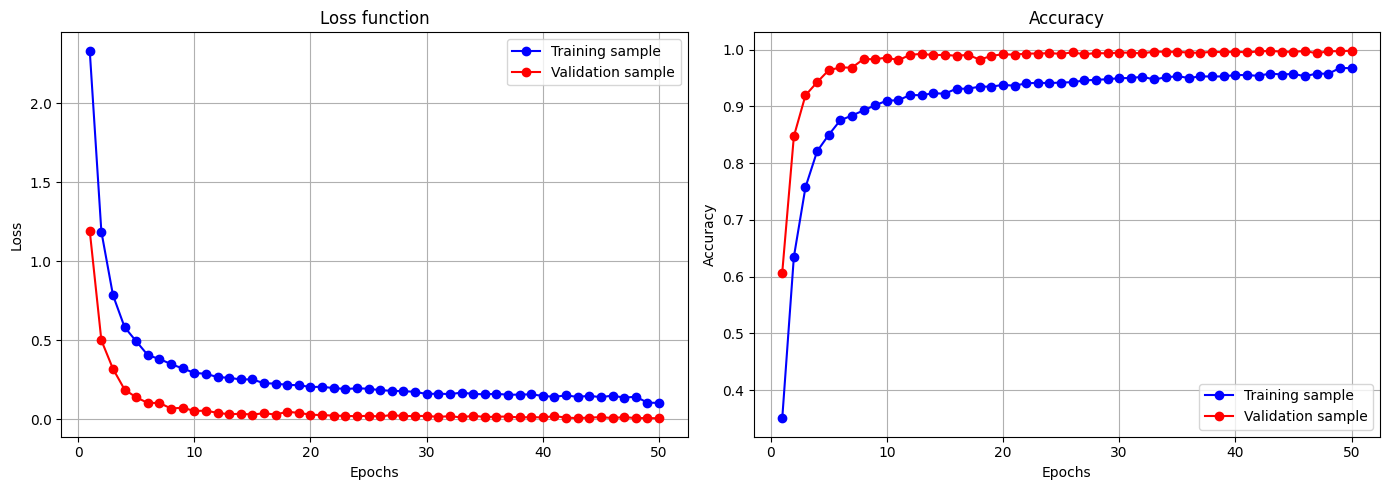

In [ ]:
import matplotlib.pyplot as plt

def plot_training_history(history):

    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(14, 5))

    # Losses
    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, 'bo-', label='Training sample')
    plt.plot(epochs, val_loss, 'ro-', label='Validation sample')
    plt.title('Loss function')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    # Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, acc, 'bo-', label='Training sample')
    plt.plot(epochs, val_acc, 'ro-', label='Validation sample')
    plt.title('Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

plot_training_history(history)